# Ejercicio 5 — Reconstrucción en condiciones ideales

**Etiqueta de uso de IA:** *Asistencia para destrabar / corregir*.

Trabajamos con mediciones **ideales**, sin ruido: $b_k = A_k\,x_{\text{fantoma}}$ para
$k \in \{2,4,7\}$. Como los datos son exactos, el sistema $A_k x = b_k$ es siempre
**compatible** (por construcción $x_{\text{fantoma}}$ es solución). Lo que cambia entre los
tres casos es la *unicidad*: $A_7$ tiene rango columna completo, mientras que $A_2$ y $A_4$
tienen espacio nulo no trivial y admiten infinitas soluciones.

`np.linalg.lstsq` resuelve $\min_x \|A x - b\|^2$ vía SVD y, cuando la solución no es única,
devuelve la de **norma mínima**, es decir la única solución que además pertenece a
$\operatorname{Fil}(A) = \operatorname{Nul}(A)^{\perp}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("figuras", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "image.cmap": "gray"})


def guardar(fig, nombre):
    # Guarda la figura en figuras/, como pide el formato de entrega.
    fig.savefig(os.path.join("figuras", nombre + ".png"), bbox_inches="tight", dpi=150)


X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8
x_fantoma = X_fantoma.reshape(-1)   # k = i*n + j


def mascara_rayo(n, direccion, s):
    # M[i,j] = 1  <=>  alpha*i + beta*j == s
    alpha, beta = direccion
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    # Devuelve A (m x n^2) y la lista de pares ((alpha, beta), s) de cada fila.
    i = np.arange(n).reshape(n, 1)
    j = np.arange(n).reshape(1, n)
    filas, info = [], []
    for direccion in direcciones:
        alpha, beta = direccion
        valores_s = np.unique(alpha * i + beta * j)   # np.unique ya devuelve ordenado
        for s in valores_s:
            filas.append(mascara_rayo(n, direccion, int(s)).reshape(-1))
            info.append((direccion, int(s)))
    return np.array(filas, dtype=float), info


D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]


A2, _ = matriz_proyeccion(n, D2)
A4, _ = matriz_proyeccion(n, D4)
A7, _ = matriz_proyeccion(n, D7)
matrices = {2: A2, 4: A4, 7: A7}

for k, A in matrices.items():
    print(f"A{k}: {str(A.shape):>10}   rango = {np.linalg.matrix_rank(A):>2}   "
          f"dim Nul = {64 - np.linalg.matrix_rank(A):>2}")

A2:   (16, 64)   rango = 15   dim Nul = 49
A4:   (46, 64)   rango = 39   dim Nul = 25
A7:  (119, 64)   rango = 64   dim Nul =  0


## a) Mediciones ideales y resolución con `lstsq`

In [2]:
reconstrucciones = {}
mediciones = {}

for k, A in matrices.items():
    b = A @ x_fantoma
    x_hat, residuos_lstsq, rango_lstsq, sv = np.linalg.lstsq(A, b, rcond=None)
    mediciones[k] = b
    reconstrucciones[k] = x_hat
    print(f"A{k}:  b ∈ R^{b.shape[0]}   rango informado por lstsq = {rango_lstsq}")

A2:  b ∈ R^16   rango informado por lstsq = 15
A4:  b ∈ R^46   rango informado por lstsq = 39
A7:  b ∈ R^119   rango informado por lstsq = 64


## b) Residuo y error relativo

Para cada reconstrucción calculamos

$$r_k = b_k - A_k \hat{x}_k, \qquad
\text{error relativo} = \frac{\|\hat{x}_k - x_{\text{fantoma}}\|}{\|x_{\text{fantoma}}\|}.$$

Son dos cosas muy distintas: el residuo mide el desajuste **en el espacio de las
mediciones** (lo único observable), mientras que el error relativo mide la distancia
**en el espacio de las imágenes** (que en la práctica no se puede calcular, porque no se
conoce el original).

In [3]:
encabezado = (f"{'k':>2} {'dim(A_k)':>11} {'rango':>6} {'dim Nul':>8} "
              f"{'||r_k||':>12} {'error rel.':>12}")
print(encabezado)
print("-" * len(encabezado))

resumen = {}
for k, A in matrices.items():
    b = mediciones[k]
    x_hat = reconstrucciones[k]
    r = b - A @ x_hat
    norma_r = np.linalg.norm(r)
    err_rel = np.linalg.norm(x_hat - x_fantoma) / np.linalg.norm(x_fantoma)
    rango = np.linalg.matrix_rank(A)
    resumen[k] = (norma_r, err_rel, rango)
    print(f"{k:>2} {str(A.shape):>11} {rango:>6} {64 - rango:>8} "
          f"{norma_r:>12.3e} {err_rel:>12.3e}")

 k    dim(A_k)  rango  dim Nul      ||r_k||   error rel.
--------------------------------------------------------
 2    (16, 64)     15       49    4.263e-15    4.689e-01
 4    (46, 64)     39       25    1.623e-14    1.365e-01
 7   (119, 64)     64        0    1.532e-14    2.107e-15


In [4]:
# La solución de norma mínima es, en efecto, la de menor norma entre las compatibles.
print(f"{'k':>2} {'||x_fantoma||':>14} {'||x_hat_k||':>13}")
print("-" * 31)
for k in matrices:
    print(f"{k:>2} {np.linalg.norm(x_fantoma):>14.4f} "
          f"{np.linalg.norm(reconstrucciones[k]):>13.4f}")
print()
print("Para k = 2 y 4 la reconstrucción tiene norma MENOR que el fantoma: lstsq eligió")
print("el representante de norma mínima del conjunto afín de soluciones, descartando")
print("toda componente en Nul(A_k).")

 k  ||x_fantoma||   ||x_hat_k||
-------------------------------
 2         2.5357        2.2397
 4         2.5357        2.5120
 7         2.5357        2.5357

Para k = 2 y 4 la reconstrucción tiene norma MENOR que el fantoma: lstsq eligió
el representante de norma mínima del conjunto afín de soluciones, descartando
toda componente en Nul(A_k).


### Lectura de la tabla

- Los tres residuos son del orden de $10^{-14}$, o sea **cero numérico**. Era esperable:
  los datos son ideales y provienen exactamente del modelo, así que en los tres casos existe
  al menos una imagen que reproduce las mediciones a la perfección.
- El error relativo, en cambio, es muy distinto: $\approx 47\%$ para $A_2$, $\approx 14\%$
  para $A_4$ y $\approx 10^{-15}$ (exacto) para $A_7$. Ese salto es exactamente la diferencia
  entre tener o no espacio nulo.
- Se cumple la relación teórica: como $\hat{x}_k$ es la solución de norma mínima,
  $\hat{x}_k = P_{\operatorname{Fil}(A_k)}\,x_{\text{fantoma}}$, la proyección ortogonal del
  fantoma sobre el complemento ortogonal del espacio nulo. El error es entonces exactamente
  la componente del fantoma que vive en $\operatorname{Nul}(A_k)$. Lo verificamos:

In [5]:
for k, A in matrices.items():
    U, S, Vt = np.linalg.svd(A)
    rango = np.linalg.matrix_rank(A)
    base_nulo = Vt[rango:]                                  # base de Nul(A)
    componente_nula = base_nulo.T @ (base_nulo @ x_fantoma)  # proyección sobre Nul(A)
    error = x_fantoma - reconstrucciones[k]
    print(f"A{k}:  ||proy_Nul(x_fantoma)|| = {np.linalg.norm(componente_nula):.6f}   "
          f"||x_fantoma - x_hat|| = {np.linalg.norm(error):.6f}   "
          f"¿iguales? {np.allclose(componente_nula, error, atol=1e-8)}")

A2:  ||proy_Nul(x_fantoma)|| = 1.189078   ||x_fantoma - x_hat|| = 1.189078   ¿iguales? True
A4:  ||proy_Nul(x_fantoma)|| = 0.346029   ||x_fantoma - x_hat|| = 0.346029   ¿iguales? True
A7:  ||proy_Nul(x_fantoma)|| = 0.000000   ||x_fantoma - x_hat|| = 0.000000   ¿iguales? True


## c) Visualización: original, reconstrucción y diferencia

Usamos **la misma escala de color** en los nueve paneles para que las comparaciones sean
honestas: si cada panel se autoescalara, una diferencia minúscula se vería tan contrastada
como el fantoma entero.

escala de color común: [-0.220, 0.800]


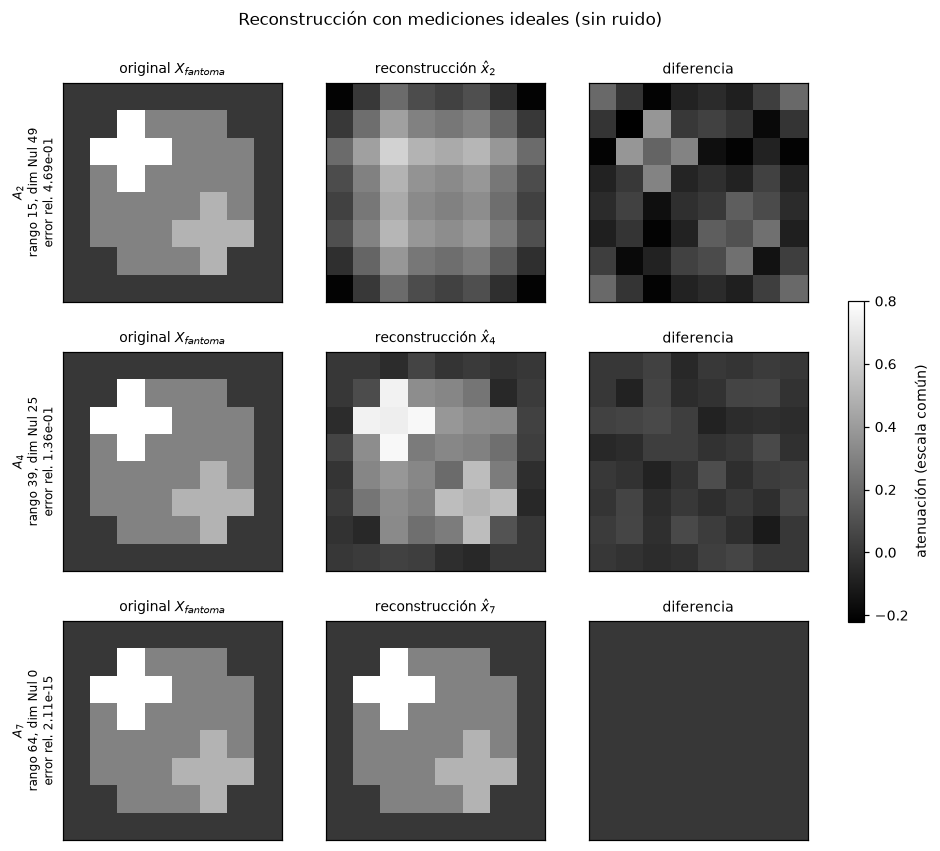

In [6]:
todos = [X_fantoma] + [reconstrucciones[k].reshape(n, n) for k in matrices] \
        + [(x_fantoma - reconstrucciones[k]).reshape(n, n) for k in matrices]
vmin = min(M.min() for M in todos)
vmax = max(M.max() for M in todos)
print(f"escala de color común: [{vmin:.3f}, {vmax:.3f}]")

fig, axes = plt.subplots(3, 3, figsize=(9.4, 9.0))
for fila, k in enumerate(matrices):
    X_hat = reconstrucciones[k].reshape(n, n)
    diferencia = X_fantoma - X_hat
    norma_r, err_rel, rango = resumen[k]

    paneles = [
        (X_fantoma, "original $X_{fantoma}$"),
        (X_hat, f"reconstrucción $\\hat{{x}}_{{{k}}}$"),
        (diferencia, "diferencia"),
    ]
    for col, (M, titulo) in enumerate(paneles):
        ax = axes[fila, col]
        im = ax.imshow(M, cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(titulo, fontsize=9)
    axes[fila, 0].set_ylabel(f"$A_{{{k}}}$\nrango {rango}, dim Nul {64 - rango}\n"
                             f"error rel. {err_rel:.2e}", fontsize=8)
    axes[fila, 0].set_yticks([])

fig.colorbar(im, ax=axes, fraction=0.02, label="atenuación (escala común)")
fig.suptitle("Reconstrucción con mediciones ideales (sin ruido)", y=0.95)
guardar(fig, "ejercicio_05c_reconstrucciones")
plt.show()

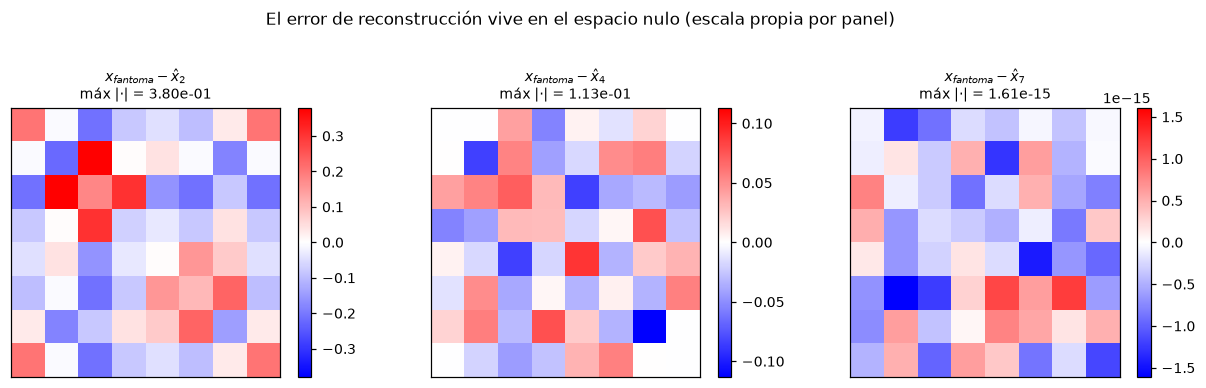

In [7]:
# Ampliamos las diferencias con su propia escala, para ver su ESTRUCTURA.
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.3))
for ax, k in zip(axes, matrices):
    diferencia = (x_fantoma - reconstrucciones[k]).reshape(n, n)
    lim = max(np.abs(diferencia).max(), 1e-16)
    im = ax.imshow(diferencia, cmap="bwr", vmin=-lim, vmax=lim)
    ax.set_title(f"$x_{{fantoma}} - \\hat{{x}}_{{{k}}}$\nmáx |·| = {lim:.2e}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("El error de reconstrucción vive en el espacio nulo (escala propia por panel)",
             y=1.05)
fig.tight_layout()
guardar(fig, "ejercicio_05c_diferencias")
plt.show()

### ¿Por qué un residuo cercano a cero no garantiza haber recuperado la imagen?

Porque el residuo y el error miden cosas en espacios diferentes:

$$\underbrace{\|b_k - A_k\hat{x}_k\|}_{\text{residuo: en } \mathbb{R}^{m}}
\qquad\text{vs.}\qquad
\underbrace{\|\hat{x}_k - x_{\text{fantoma}}\|}_{\text{error: en } \mathbb{R}^{64}} .$$

Si $\hat{x}_k$ es solución exacta, entonces
$A_k(\hat{x}_k - x_{\text{fantoma}}) = b_k - b_k = 0$, o sea

$$\hat{x}_k - x_{\text{fantoma}} \in \operatorname{Nul}(A_k).$$

El residuo **no ve** el error, porque el error está justamente en la dirección que $A_k$
aniquila. Cuando $\operatorname{Nul}(A_k) \ne \{0\}$ podemos tener residuo exactamente cero
y un error de reconstrucción arbitrariamente grande: basta desplazarse dentro del espacio
nulo. Es lo que muestran las tres filas de la figura:

- **$A_2$** (dim Nul $= 49$): el residuo es $\sim 10^{-14}$ y sin embargo el error relativo
  es del $47\%$. La reconstrucción de norma mínima conserva sólo la información de sumas por
  filas y columnas y "reparte" esa masa de la forma más uniforme posible; el resultado es una
  versión borrosa donde se perdió toda la estructura interna.
- **$A_4$** (dim Nul $= 25$): el error baja al $14\%$; se recupera bastante de la forma
  general pero persisten patrones alternados de $\pm$ (los elementos del espacio nulo del
  Ejercicio 4).
- **$A_7$** (dim Nul $= 0$): acá sí residuo cero $\Rightarrow$ error cero. Con rango columna
  completo la solución es única, y como el sistema es compatible esa única solución es
  exactamente $x_{\text{fantoma}}$.

**Conclusión.** El residuo sólo certifica consistencia con los datos, no fidelidad a la
verdad. En un problema real no tenemos con qué comparar: la única garantía de que un residuo
chico implique una reconstrucción correcta es que la matriz de proyección tenga rango
columna completo, y eso se logra eligiendo bien las orientaciones de medición. Aun así, el
Ejercicio 6 mostrará que rango completo garantiza unicidad pero **no** estabilidad: con
ruido, un residuo chico puede seguir conviviendo con una reconstrucción mala.